# **MÓDULO 33 - Projeto Final de Modelos Avançados**

**Objetivo do Projeto:**

O objetivo deste projeto é aplicar os conceitos aprendidos nos módulos de conceitos avançados de modelagem para realizar uma segmentação de clientes utilizando o algoritmo de clustering K-Means. Ao final do projeto, você terá a oportunidade de consolidar seus conhecimentos em exploração de dados, pré-processamento, implementação e avaliação de modelos.

**Exploração de Dados:**

Inicie explorando o dataset fornecido, buscando entender as principais características das variáveis e a distribuição dos dados.

Realize análises descritivas, identifique padrões, e verifique a presença de valores ausentes ou inconsistências que precisem ser tratadas.

**Tratamento de Dados:**

Realize os tratamentos necessários como limpeza de dados, normalização ou padronização das variáveis, e, se necessário, a criação de variáveis derivadas.

Documente cada etapa do tratamento, explicando o motivo das escolhas feitas e como elas impactam no modelo.

**Implementação do Algoritmo K-Means:**

Aplique o algoritmo K-Means no dataset tratado. Defina o número de clusters (k).
Execute o algoritmo, ajuste os parâmetros conforme necessário, e documente o processo.

**Avaliação e Interpretação dos Resultados:**

Avalie a qualidade dos clusters gerados utilizando métricas adequadas.

Interprete os resultados, descrevendo as características de cada cluster e como eles podem ser utilizados para a segmentação de clientes.

Sugira aplicações práticas para os clusters identificados, como estratégias de marketing direcionadas ou personalização de ofertas.

**O dataset a ser utilizado neste projeto contém informações de 200 clientes, com os seguintes atributos:**

CustomerID: Identificador único atribuído a cada cliente.

Gender: Gênero do cliente.

Age: Idade do cliente.

Annual Income (k$): Renda anual do cliente em milhares de dólares.

Spending Score (1-100): Pontuação atribuída pelo shopping com base no
comportamento e padrão de gastos do cliente.

Notem que neste projeto vocês terão autonomia para criar os passos e justificar, sempre, os passos escolhidos.

In [66]:
import pandas as pd
import numpy as np
df = pd.read_csv('Mall_Customers.csv', delimiter= ',')
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


# Estrutura geral dos dados

In [67]:
print("Tamanho:\n", df.shape)
print("\n")
df.info()

Tamanho:
 (200, 5)


<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB


In [68]:
df.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [69]:
df.duplicated().sum()

np.int64(0)

In [70]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


# Aprofundamento da observação sobre os intervalos:

- os valores das colunas 'Annual Income (k$)' e 'Spending Score (1-100)' possuem diferenças de mínimo e máximo bem extensas;
- Age vai de 18 a 70
- Annual Income vai de 15 a 137 e está em milhares de dólares
- Spending Score vai de 1 a 99 e é uma pontuação
- Nenhum valor nulo e nenhum valor duplicado;

In [71]:
distribuicao_genero = df['Gender'].value_counts()
distribuicao_genero

Gender
Female    112
Male       88
Name: count, dtype: int64

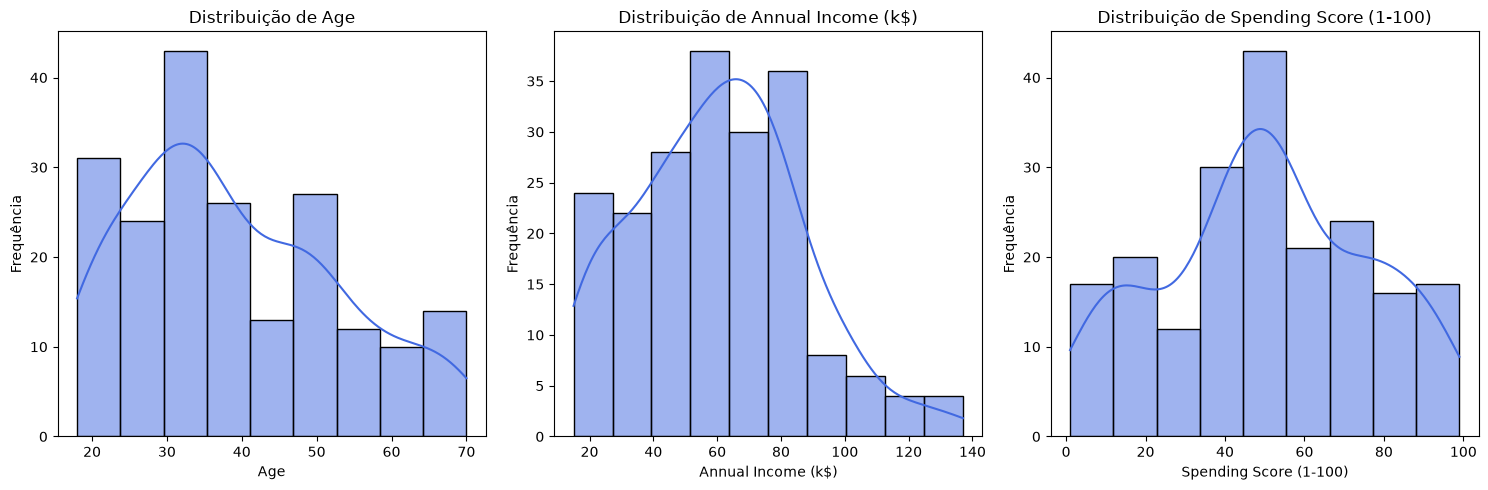

In [72]:
import matplotlib.pyplot as plt
import seaborn as sns
colunas_numericas = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for i, col in enumerate(colunas_numericas):
    sns.histplot(df[col], bins='auto', kde=True, ax=axes[i], color='royalblue', edgecolor='black')
    axes[i].set_title(f'Distribuição de {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequência')

plt.tight_layout()
plt.show()

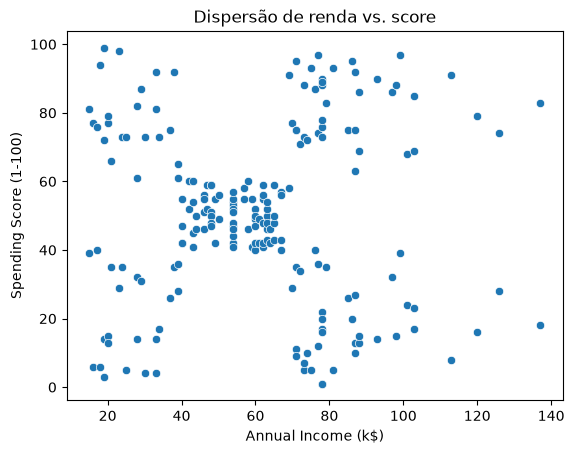

In [73]:
sns.scatterplot(x='Annual Income (k$)', y='Spending Score (1-100)', data=df)
plt.title("Dispersão de renda vs. score")
plt.show()

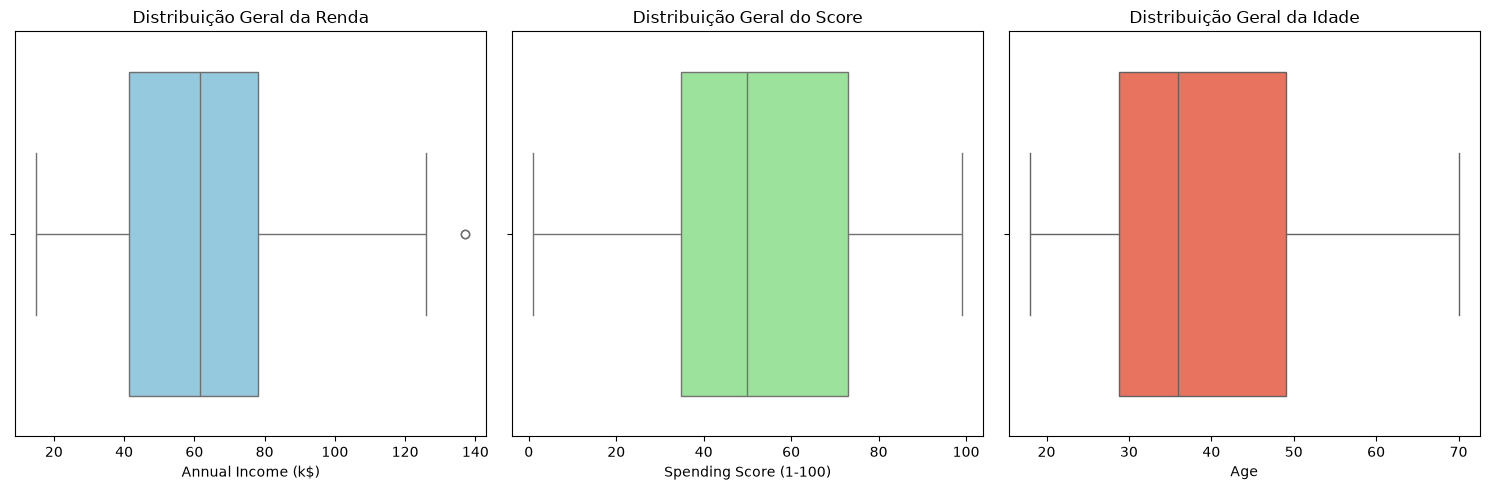

In [77]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.boxplot(x=df["Annual Income (k$)"], ax=axes[0], color="skyblue")
axes[0].set_title("Distribuição Geral da Renda")

sns.boxplot(x=df["Spending Score (1-100)"], ax=axes[1], color="lightgreen")
axes[1].set_title("Distribuição Geral do Score")

sns.boxplot(x=df["Age"], ax=axes[2], color="tomato")
axes[2].set_title("Distribuição Geral da Idade")

plt.tight_layout()
plt.show()

# Aprofundamento das observações dos gráficos (observo 5 grupos distintos):

- 1º grupo spending score entre "60 e 100" com anual income em milhares de doláres entre "15 a 40"
- 2º grupo spending score entre "1 e 40" com anual income em milhares de doláres entre "15 a 40"
- 3º grupo spending score entre "40 e 60" com anual income em milhares de doláres entre "40 a 70"
- 4º grupo spending score entre "60 e 100" com anual income em milhares de doláres entre "60 e 100"
- 5º grupo spending score entre "1 e 40" com anual income em milhares de doláres entre "70 e 110"

- Observa-se que 137k de Annual Income é um outlier no conjunto de dados que estamos trabalhamos.

Para proteção dos dados geralmente o número do CustomerID não deveria entrar no modelo, além de que o ID é só um número sequencial, sem significado. O K-Means trata tudo como número, então acharia que os clientes 1 e 2 são “parecidos” só porque os IDs estão próximos. No ddataframe o número de ID acompanha a renda, então colocar o ID no modelo seria contar a renda duas vezes, de um jeito artificial.

In [99]:
total_abaixo_100k = (df["Annual Income (k$)"] < 100).sum()
total_acima_100k = (df["Annual Income (k$)"] > 100).sum()
total_acima_110k = (df["Annual Income (k$)"] > 110).sum()
total_acima_120k = (df["Annual Income (k$)"] > 120).sum()
total_acima_132k = (df["Annual Income (k$)"] > 132.75).sum()
total_geral = len(df)
porcentagem_abaixo_100k = (total_abaixo_100k / total_geral) * 100
porcentagem_100k = (total_acima_100k / total_geral) * 100
porcentagem_110k = (total_acima_110k / total_geral) * 100
porcentagem_120k = (total_acima_120k / total_geral) * 100
porcentagem_132k = (total_acima_132k / total_geral) * 100

resumo_tabela = pd.DataFrame(
    {
        "Métrica": [
            "Pessoas com Renda (abaixo) < 100k",
            "Pessoas com Renda > 100k",
            "Pessoas com Renda > 110k",
            "Pessoas com Renda > 120k",
            "Pessoas com Renda > 132k",
            "Total de Pessoas na Base",
            "Percentual do ABAIXO_100k",
            "Percentual do Total_100k",
            "Percentual do Total_110k",
            "Percentual do Total_120k",
            "Percentual do Total_132k",
        ],
        "Valor": [
            f"{total_abaixo_100k} pessoas",
            f"{total_acima_100k} pessoas",
            f"{total_acima_110k} pessoas",
            f"{total_acima_120k} pessoas",
            f"{total_acima_130k} pessoas",
            f"{total_geral} pessoas",
            f"{porcentagem_abaixo_100k:.2f}%",
            f"{porcentagem_100k:.2f}%",
            f"{porcentagem_110k:.2f}%",
            f"{porcentagem_120k:.2f}%",
            f"{porcentagem_132k:.2f}%",
        ],
    }
)

print(resumo_tabela)

                              Métrica        Valor
0   Pessoas com Renda (abaixo) < 100k  186 pessoas
1            Pessoas com Renda > 100k   14 pessoas
2            Pessoas com Renda > 110k    8 pessoas
3            Pessoas com Renda > 120k    4 pessoas
4            Pessoas com Renda > 132k    2 pessoas
5            Total de Pessoas na Base  200 pessoas
6           Percentual do ABAIXO_100k       93.00%
7            Percentual do Total_100k        7.00%
8            Percentual do Total_110k        4.00%
9            Percentual do Total_120k        2.00%
10           Percentual do Total_132k        1.00%


In [95]:
Q1 = df['Annual Income (k$)'].quantile(0.25)
Q3 = df['Annual Income (k$)'].quantile(0.75)
IQR = Q3 - Q1
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print(f"Q1 (25%): {Q1}")
print(f"Q3 (75%): {Q3}")
print(f"IQR: {IQR}")
print(f"Limite inferior para Outliers: {limite_inferior}")
print(f"Limite superior para Outliers: {limite_superior}")

Q1 (25%): 41.5
Q3 (75%): 78.0
IQR: 36.5
Limite inferior para Outliers: -13.25
Limite superior para Outliers: 132.75


Acima de 132.75 há 1% da população da amostra com 200 participantes. Não vou retirá-los do tratamento pois esses valores são possíveis
e reais, descartando um erro de digitação ou um valor irreal. Para o gênero observa-se 112 mulheres e 88 homens, ou seja, 56% e 44%.

Para uma campanha de marketing acredito que a idade e o salário anual segmentaria de forma mais assertiva as tendências de compras 
e gastos de um grupo.

In [100]:
df_copy = df[['Annual Income (k$)', 'Age']].copy()

As variáveis idade e salário anual possuem intervalos de 18 a 70 e de 15 a 137, respectivamente. Desse modo quem empregaria mais
peso para cálculo seria o salário anual.

In [103]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
df_scaled_array = scaler.fit_transform(df_copy)
df_scaled = pd.DataFrame(df_scaled_array, columns=df_copy.columns)
df_scaled.head()

,Annual Income (k$),Age
0,-1.738999,-1.424569
1,-1.738999,-1.281035
2,-1.700830,-1.352802
3,-1.700830,-1.137502
4,-1.662660,-0.563369


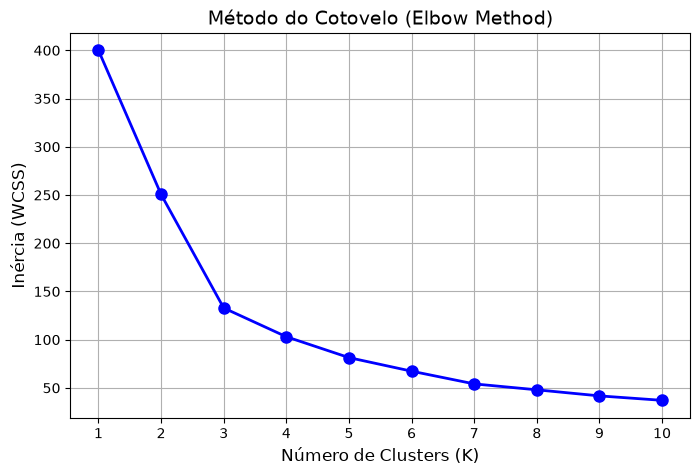

In [104]:
from sklearn.cluster import KMeans

inercia = []

valores_k = range(1, 11)

for k in valores_k:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(df_scaled)
    inercia.append(kmeans.inertia_)
    
plt.figure(figsize=(8, 5))
plt.plot(valores_k, inercia, "bo-", linewidth=2, markersize=8)
plt.title("Método do Cotovelo (Elbow Method)", fontsize=14)
plt.xlabel("Número de Clusters (K)", fontsize=12)
plt.ylabel("Inércia (WCSS)", fontsize=12)
plt.xticks(valores_k)
plt.grid(True)
plt.show()

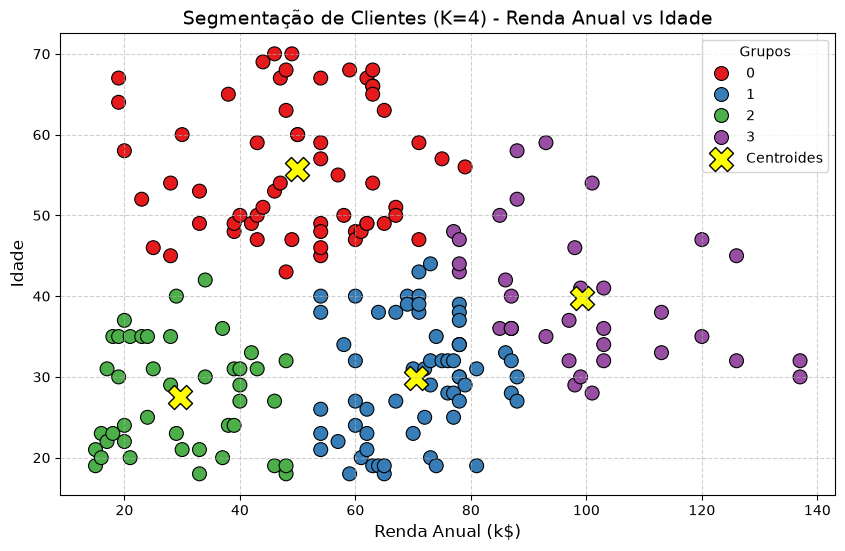

In [105]:
import seaborn as sns

kmeans_final = KMeans(n_clusters=4, random_state=42, n_init=10)
clusters = kmeans_final.fit_predict(df_scaled)

df_scaled["Cluster"] = clusters
df["Cluster"] = clusters

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x="Annual Income (k$)",
    y="Age",
    hue="Cluster",
    data=df,
    palette="Set1",
    s=100,
    edgecolor="black",
)

centroids_scaled = kmeans_final.cluster_centers_
centroids_original = scaler.inverse_transform(centroids_scaled)
plt.scatter(
    centroids_original[:, 0],
    centroids_original[:, 1],
    s=300,
    c="yellow",
    marker="X",
    edgecolor="black",
    label="Centroides",
)

plt.title("Segmentação de Clientes (K=4) - Renda Anual vs Idade", fontsize=14)
plt.xlabel("Renda Anual (k$)", fontsize=12)
plt.ylabel("Idade", fontsize=12)
plt.legend(title="Grupos")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()


In [106]:
analise_perfil = (
    df.groupby("Cluster")[["Age", "Annual Income (k$)", "Spending Score (1-100)"]]
    .mean()
    .reset_index()
)
print(analise_perfil)

   Cluster        Age  Annual Income (k$)  Spending Score (1-100)
0        0  55.716667           49.916667               40.516667
1        1  29.838710           70.467742               56.677419
2        2  27.511628           29.697674               59.790698
3        3  39.828571           99.171429               43.542857


Interpretação dos Clusters (Médias)

• Cluster 0 — Seniores Moderados: Idade média avançada (~56 anos), renda intermediária (~50k) e gastos moderados (~40.5).
É um público maduro e conservador nas compras.
• Cluster 1 — Jovens Adultos Consumistas: Idade jovem (~30 anos), ótima renda (~70.5k) e gastos acima da média (~56.7).
Público ativo e altamente lucrativo.
• Cluster 2 — Jovens de Baixa Renda (Impulsivos): O grupo mais jovem (~27.5 anos), menor renda (~29.7k), mas com o maior score de gastos (~59.8).
Compram por impulso e são atraídos por tendências e promoções.
• Cluster 3 — Adultos de Alta Renda (Seletivos): Faixa dos ~40 anos, possuem a maior renda da base (~99.2k), mas gastos moderados (~43.5).
São seletivos e buscam qualidade, status e exclusividade.

Aplicações Práticas de Marketing

• Estratégia para o Cluster 3 (Alta Renda): Foco em produtos Premium e de luxo. Criação de programas de fidelidade VIP,
serviços exclusivos (como valet ou lounge) e eventos de marcas selecionadas.
• Estratégia para o Cluster 1 (Jovens Adultos): Campanhas digitais via redes sociais com foco em lançamentos de moda,
tecnologia, restaurantes e experiências de estilo de vida.
• Estratégia para o Cluster 2 (Jovens / Alto Gasto): Campanhas baseadas em descontos, cashback, parcelamento facilitado 
e promoções na praça de alimentação e cinema.
• Estratégia para o Cluster 0 (Seniores): Comunicação tradicional e direta. Foco em produtos de conforto, bem-estar, 
saúde e datas familiares.